In [1]:
#Load pipeline execution history

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display

monitor_dir = Path("outputs/monitoring")
history_file = monitor_dir / "run_history.jsonl"

records = []

with open(history_file, encoding="utf-8") as file:
    for line in file:
        if line.strip():
            records.append(json.loads(line))

history = pd.DataFrame(records)

print("METHANESCOPE AI - MONITORING DASHBOARD")
print("Total recorded runs:", len(history))

display(history)

METHANESCOPE AI - MONITORING DASHBOARD
Total recorded runs: 1


,started_utc,command,result,failure_class,message,preflight,scientific_validation,validation_exit_code,ingestion_exit_code,latest_pipeline_audit,completed_utc,duration_seconds
0,2026-10-18T11:32:25+00:00,run-once,SUCCESS,None,Validation and transactional ingestion completed,"{'checked_utc': '2026-10-18T11:32:25+00:00', '...",NOT_ESTABLISHED,0,0,{'filename': '20261018T113225Z_ingest_summary....,2026-10-18T11:32:25+00:00,1.735


In [3]:
#Visualise pipeline execution status


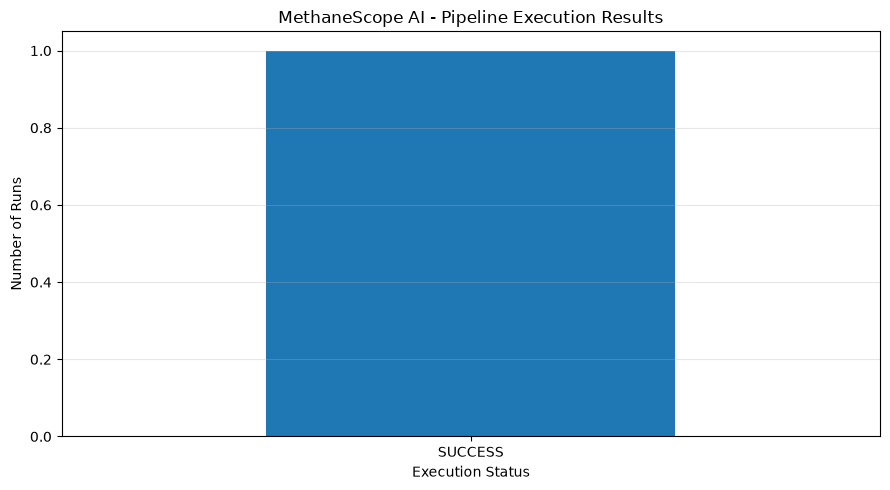

Execution summary:
result
SUCCESS    1
Name: count, dtype: int64


In [4]:
status_counts = history["result"].value_counts()

plt.figure(figsize=(9, 5))

status_counts.plot(kind="bar")

plt.title("MethaneScope AI - Pipeline Execution Results")
plt.xlabel("Execution Status")
plt.ylabel("Number of Runs")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Execution summary:")
print(status_counts)

In [5]:
#Analyse processing duration

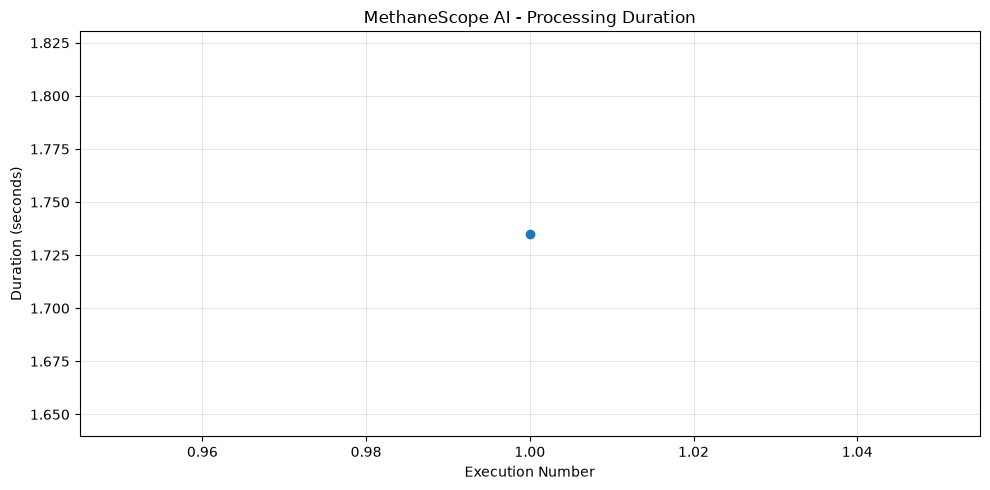

Average processing duration: 1.735 seconds


In [6]:
if "duration_seconds" in history.columns:

    durations = pd.to_numeric(
        history["duration_seconds"],
        errors="coerce"
    ).dropna()

    if not durations.empty:

        plt.figure(figsize=(10, 5))

        plt.plot(
            range(1, len(durations) + 1),
            durations,
            marker="o"
        )

        plt.title("MethaneScope AI - Processing Duration")
        plt.xlabel("Execution Number")
        plt.ylabel("Duration (seconds)")

        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

        print(
            "Average processing duration:",
            round(durations.mean(), 3),
            "seconds"
        )